# Food Delivery Demand Prediction and Customer Analytics
## Mid-term demo: medallion pipeline on 37.3 million rows

This notebook walks through the five mid-term steps on the real data, then runs a live test with deliberately broken records.

| Step | What you will see |
|---|---|
| 1. Problem | Domain, objectives, target users |
| 2. Ingest | The ingestion manifest: files, row counts, checksums, batch ID |
| 3. Bronze | Raw rows with lineage columns; row counts reconciled |
| 4. Silver | The same records before and after cleaning; data-quality report |
| 5. PySpark | Spark SQL, joins, window functions running live |
| 6. Live test | A batch of broken records goes in; the pipeline deduplicates and quarantines it |

In [1]:
import json, os, subprocess, sys, time
import pandas as pd
from IPython.display import Image, display
from pyspark.sql import SparkSession, functions as F, Window

import glob
# Spark needs Java 17; VS Code may not load ~/.zshrc, so find the project JDK directly
os.environ.setdefault("JAVA_HOME", (glob.glob(os.path.expanduser("~/tools/jdk/*/Contents/Home")) or [""])[0])
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
PROJECT = os.path.abspath("..")
DATA = f"{PROJECT}/data"
REPORTS = f"{PROJECT}/outputs/pipeline"
pd.set_option("display.max_colwidth", 60)

spark = (SparkSession.builder.appName("mid-term-demo")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 14:00:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3


## Step 1. Domain and problem

**Domain:** online food and grocery delivery.

**Problem:** a delivery platform cannot plan riders, stock or retention without knowing *when* demand arrives, *what* drives it and *which* customers are drifting away. The raw order data is large (37.3 million rows) and has type, consistency and parsing problems.

**Objectives:** traceable ingestion, an auditable raw layer, a validated clean layer, PySpark analysis of demand and customers, and an early churn signal. Prediction (MLlib) and streaming follow in the final phase.

**Target users:** operations managers (rider scheduling), category managers (stock), marketing/CRM (segments, win-back), data engineers (a reusable pipeline).

## Step 2. Collect and ingest

`01_ingest.py` downloads the CSVs from Kaggle if missing, checks every header against the expected schema, and records size, MD5 checksum and row count in a manifest with a batch ID.

In [2]:
manifest = json.load(open(f"{REPORTS}/01_ingestion_manifest.json"))
print("Batch ID:", manifest["batch_id"], "| ingested at (UTC):", manifest["ingested_at_utc"])
print("Source:", manifest["source"]["dataset"], "via", manifest["source"]["distribution"])
pd.DataFrame([{"table": t, "file": f["file"], "rows": f"{f['rows']:,}", "MB": round(f["bytes"] / 1e6, 1), "md5": f["md5"]}
              for t, f in manifest["files"].items()])

Batch ID: 20261012_141635 | ingested at (UTC): 2026-10-12T14:16:35.529755+00:00
Source: The Instacart Online Grocery Shopping Dataset 2017 via Kaggle


,table,file,rows,MB,md5
0,orders,orders.csv,"3,421,083",109.0,dd0b2f4ee716409b8e79e7b1c611a0b8
1,order_products_prior,order_products__prior.csv,"32,434,489",577.6,8bca7ad1968ee8e07760b94db74461fb
2,order_products_train,order_products__train.csv,"1,384,617",24.7,5d8f7580855097e3644ea626ee430b75
3,products,products.csv,"49,688",2.2,dfcfded9d4af77d8b747913a4cbe6ffc
4,aisles,aisles.csv,134,0.0,bc49e521faa60e1542d4a94cac3e3bb0
5,departments,departments.csv,21,0.0,18d5219db49bd50b403d39016c3ecdc5


## Step 3. Bronze layer

Raw values (all strings, nothing cleaned) in Parquet, partitioned by batch, with five lineage columns on every row.

In [3]:
bronze_orders = spark.read.parquet(f"{DATA}/bronze/orders")
bronze_orders.printSchema()
bronze_orders.limit(5).toPandas()

root
 |-- order_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- eval_set: string (nullable = true)
 |-- order_number: string (nullable = true)
 |-- order_dow: string (nullable = true)
 |-- order_hour_of_day: string (nullable = true)
 |-- days_since_prior_order: string (nullable = true)
 |-- _source_system: string (nullable = true)
 |-- _source_file: string (nullable = true)
 |-- _ingested_at: timestamp (nullable = true)
 |-- _row_hash: string (nullable = true)
 |-- _batch_id: string (nullable = true)



,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,_source_system,_source_file,_ingested_at,_row_hash,_batch_id
0,2539329,1,prior,1,2,08,NaN,kaggle:yasserh/instacart-online-grocery-basket-analysis-...,file:///Users/riverwolf/Documents/big%20data%20major%20p...,2026-10-12 19:50:16.806376,0dcf235a0affa442550894bf9fb95d7651273a450f29605278057462...,20261012_141635
1,2398795,1,prior,2,3,07,15.0,kaggle:yasserh/instacart-online-grocery-basket-analysis-...,file:///Users/riverwolf/Documents/big%20data%20major%20p...,2026-10-12 19:50:16.806376,a808df7544436ac0acfd38b6b25cd3186b2b9afa33e1fd0dc19b33a1...,20261012_141635
2,473747,1,prior,3,3,12,21.0,kaggle:yasserh/instacart-online-grocery-basket-analysis-...,file:///Users/riverwolf/Documents/big%20data%20major%20p...,2026-10-12 19:50:16.806376,e57ae0e69bc569c820d6df5cd9c0e32506aef9ee4118de21ab83d7de...,20261012_141635
3,2254736,1,prior,4,4,07,29.0,kaggle:yasserh/instacart-online-grocery-basket-analysis-...,file:///Users/riverwolf/Documents/big%20data%20major%20p...,2026-10-12 19:50:16.806376,c4609cfa431ceba53c6375bba472819637a0eb9a85228a613f4075d4...,20261012_141635
4,431534,1,prior,5,4,15,28.0,kaggle:yasserh/instacart-online-grocery-basket-analysis-...,file:///Users/riverwolf/Documents/big%20data%20major%20p...,2026-10-12 19:50:16.806376,83d8fdd0ba2916d6931aab9be18cd5863295f346bc80348a98d35aa1...,20261012_141635


In [4]:
print("Partitions (one folder per ingestion batch):", os.listdir(f"{DATA}/bronze/orders"))
audit = json.load(open(f"{REPORTS}/02_bronze_audit.json"))
pd.DataFrame(audit["tables"]).T

Partitions (one folder per ingestion batch): ['_batch_id=20261012_141635']


,landing_rows,bronze_rows,reconciled
orders,3421083,3421083,True
order_products_prior,32434489,32434489,True
order_products_train,1384617,1384617,True
products,49688,49688,True
aisles,134,134,True
departments,21,21,True


## Step 4. Silver layer

Deduplication, type casting, text standardisation, 20 validation rules with a quarantine table, and data-quality flags.

**Before and after** for the same records: an order whose gap is missing (a customer's first order), and a product whose name had extra spaces and whose category was the placeholder "missing".

In [5]:
print("BRONZE (raw strings):")
display(bronze_orders.where("order_id in ('2539329', '2398795')").select("order_id", "order_number", "order_dow", "order_hour_of_day", "days_since_prior_order").toPandas())
silver_orders = spark.read.parquet(f"{DATA}/silver/orders")
print("SILVER (typed, with derived columns and flags):")
display(silver_orders.where("order_id in (2539329, 2398795)").select("order_id", "order_number", "day_name", "order_hour", "time_of_day", "days_since_prior_order", "is_first_order", "is_gap_capped").toPandas())

BRONZE (raw strings):


,order_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,2,08,NaN
1,2398795,2,3,07,15.0


SILVER (typed, with derived columns and flags):


,order_id,order_number,day_name,order_hour,time_of_day,days_since_prior_order,is_first_order,is_gap_capped
0,2539329,1,Tuesday,8,morning,NaN,True,False
1,2398795,2,Wednesday,7,morning,15.0,False,False


In [6]:
silver_products = spark.read.parquet(f"{DATA}/silver/products")
cleaned = silver_products.where("name_was_cleaned AND is_unknown_category").limit(1).collect()[0]
print("BRONZE:")
display(spark.read.parquet(f"{DATA}/bronze/products").where(F.col("product_id") == str(cleaned.product_id)).select("product_id", "product_name", "aisle_id", "department_id").toPandas())
print("SILVER:")
display(silver_products.where(F.col("product_id") == cleaned.product_id).select("product_id", "product_name", "aisle", "department", "is_unknown_category", "name_was_cleaned").toPandas())

BRONZE:


,product_id,product_name,aisle_id,department_id
0,31003,Broccoli Bunch,100,21


SILVER:


,product_id,product_name,aisle,department,is_unknown_category,name_was_cleaned
0,31003,Broccoli Bunch,unknown,unknown,True,True


In [7]:
dq = json.load(open(f"{REPORTS}/03_silver_dq_report.json"))
display(pd.DataFrame({t: {k: v[k] for k in ["bronze_rows", "duplicates_removed", "quarantined", "silver_rows"]} for t, v in dq.items()}).T)
pd.DataFrame([{"table": t, "flag": f, "rows": n} for t, v in dq.items() for f, n in v.get("flags", {}).items()])

,bronze_rows,duplicates_removed,quarantined,silver_rows
orders,3421083,0,0,3421083
products,49688,0,0,49688
order_items,33819106,0,0,33819106


,table,flag,rows
0,orders,is_first_order (gap legitimately missing),206209
1,orders,is_gap_capped (gap recorded as 30 = '30 or more'),369323
2,products,name_was_cleaned (extra whitespace removed),408
3,products,"is_duplicate_name (same name, different product_id)",274
4,products,is_unknown_category ('missing' -> 'unknown'),1258


## Step 5. PySpark processing (running live)

The same Silver tables, queried live with Spark SQL, joins and window functions.

In [8]:
silver_orders.createOrReplaceTempView("orders")
t = time.time()
peak = spark.sql('''
    SELECT day_name, order_hour, orders,
           RANK() OVER (PARTITION BY day_name ORDER BY orders DESC) AS rank_in_day
    FROM (SELECT day_name, order_hour, COUNT(*) AS orders FROM orders GROUP BY day_name, order_hour)
''').where("rank_in_day = 1").orderBy(F.desc("orders"))
display(peak.toPandas())
print(f"Busiest hour of each day over {silver_orders.count():,} orders in {time.time() - t:.1f}s")

,day_name,order_hour,orders,rank_in_day
0,Monday,10,55671,1
1,Sunday,14,54552,1
2,Tuesday,10,39230,1
3,Saturday,14,38748,1
4,Friday,10,38313,1
5,Wednesday,10,36040,1
6,Thursday,10,35034,1


Busiest hour of each day over 3,421,083 orders in 0.7s


In [9]:
# grouped by product_id, not name: 274 products share a name with another product
items = spark.read.parquet(f"{DATA}/silver/order_items").where("eval_set = 'prior'")
t = time.time()
w = Window.partitionBy("department").orderBy(F.desc("times_ordered"))
top3 = (items.join(F.broadcast(silver_products.select("product_id", "product_name", "department")), "product_id")
        .groupBy("department", "product_id", "product_name").agg(F.count("*").alias("times_ordered"), F.round(F.avg(F.col("reordered").cast("int")), 3).alias("reorder_rate"))
        .withColumn("rank", F.row_number().over(w)).where("rank <= 3").drop("product_id")
        .where(F.col("department").isin("produce", "dairy eggs", "snacks", "beverages")).orderBy("department", "rank"))
display(top3.toPandas())
print(f"Top 3 products per department from 32.4M order lines in {time.time() - t:.1f}s (broadcast join + row_number window)")

,department,product_name,times_ordered,reorder_rate,rank
0,beverages,Sparkling Water Grapefruit,75886,0.771,1
1,beverages,Spring Water,56087,0.812,2
2,beverages,Lime Sparkling Water,46546,0.742,3
3,dairy eggs,Organic Whole Milk,137905,0.830,1
4,dairy eggs,Organic Half & Half,76360,0.781,2
5,dairy eggs,Half & Half,69217,0.762,3
6,produce,Banana,472565,0.844,1
7,produce,Bag of Organic Bananas,379450,0.833,2
8,produce,Organic Strawberries,264683,0.778,3
9,snacks,Lightly Salted Baked Snap Pea Crisps,24950,0.628,1


Top 3 products per department from 32.4M order lines in 1.2s (broadcast join + row_number window)


In [10]:
# lag() and a rolling window: is customer 1 slowing down?
w = Window.partitionBy("user_id").orderBy("order_number")
(silver_orders.where("user_id = 1 AND eval_set = 'prior' AND NOT is_first_order")
 .withColumn("previous_gap", F.lag("days_since_prior_order").over(w))
 .withColumn("rolling_avg_last_3", F.round(F.avg("days_since_prior_order").over(w.rowsBetween(-2, 0)), 1))
 .select("order_number", "days_since_prior_order", "previous_gap", "rolling_avg_last_3").toPandas())

,order_number,days_since_prior_order,previous_gap,rolling_avg_last_3
0,2,15,NaN,15.0
1,3,21,15.0,18.0
2,4,29,21.0,21.7
3,5,28,29.0,26.0
4,6,19,28.0,25.3
5,7,20,19.0,22.3
6,8,14,20.0,17.7
7,9,0,14.0,11.3
8,10,30,0.0,14.7


In [11]:
pd.read_csv(f"{REPORTS}/processing/customer_segments.csv")

,segment,customers,avg_orders,avg_days_between,avg_basket,avg_reorder_ratio,total_items,pct_customers,pct_items
0,Power Shoppers,26080,31.1,6.8,14.1,0.575,11207366,12.6,34.6
1,Frequent Top-up,25473,30.5,6.5,5.8,0.536,4646674,12.4,14.3
2,Regulars,103104,12.9,14.6,10.1,0.432,13631896,50.0,42.0
3,Occasional Bulk,12523,6.0,24.7,18.4,0.339,1392845,6.1,4.3
4,Light / At-risk,39029,5.8,25.0,6.8,0.300,1555708,18.9,4.8


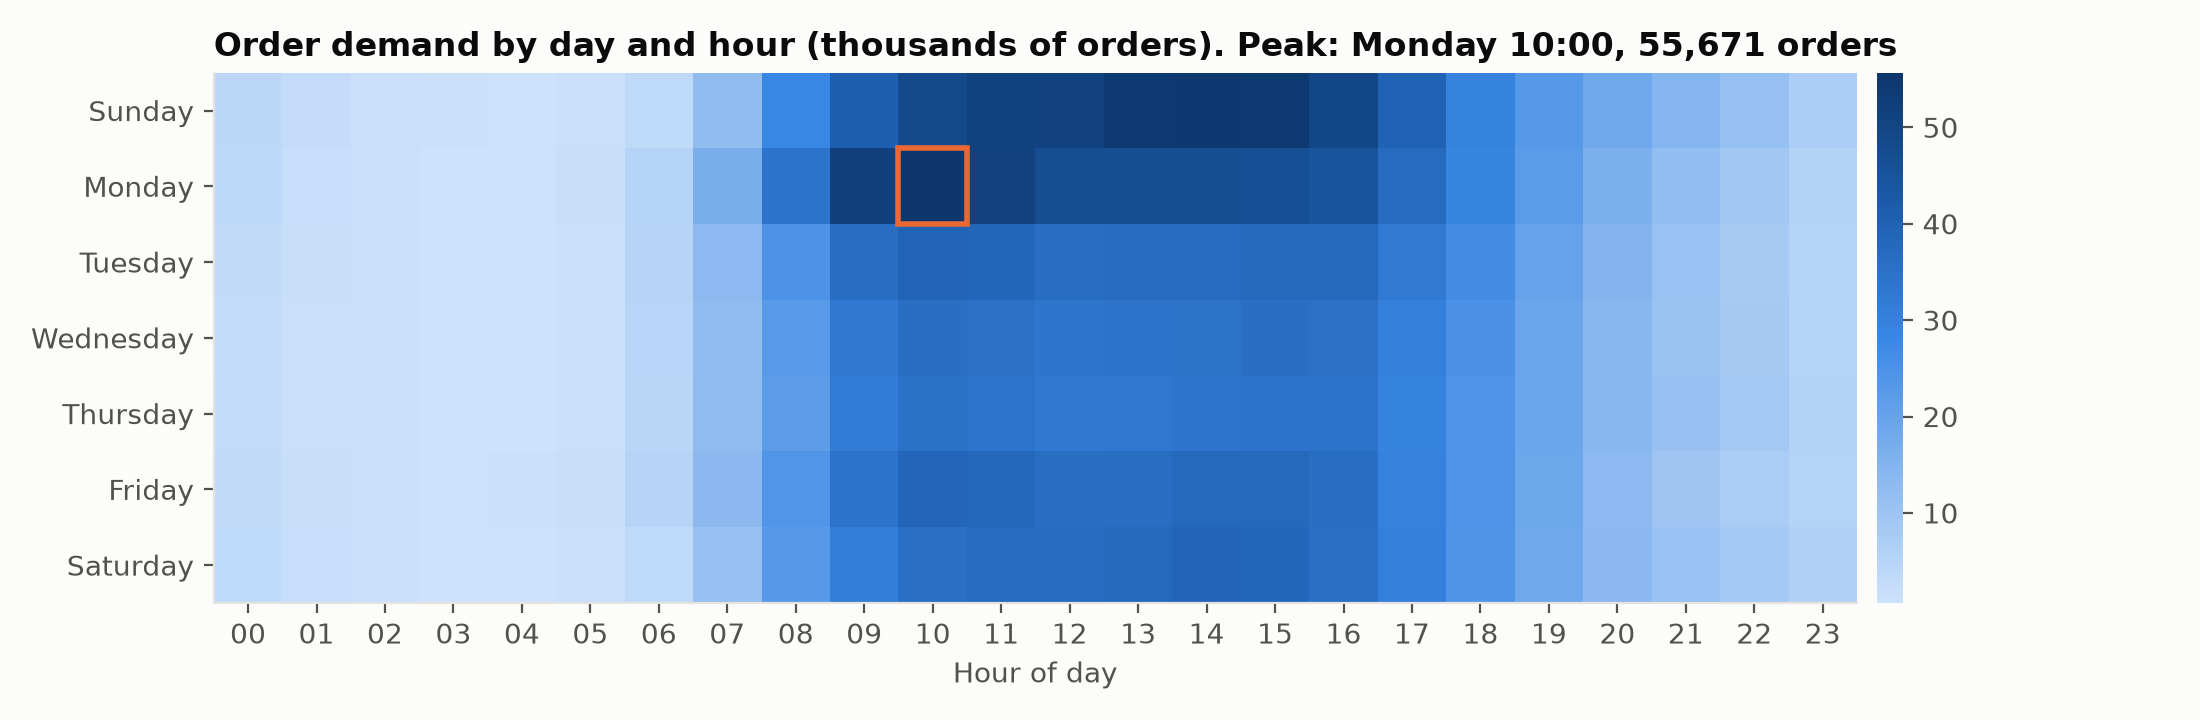

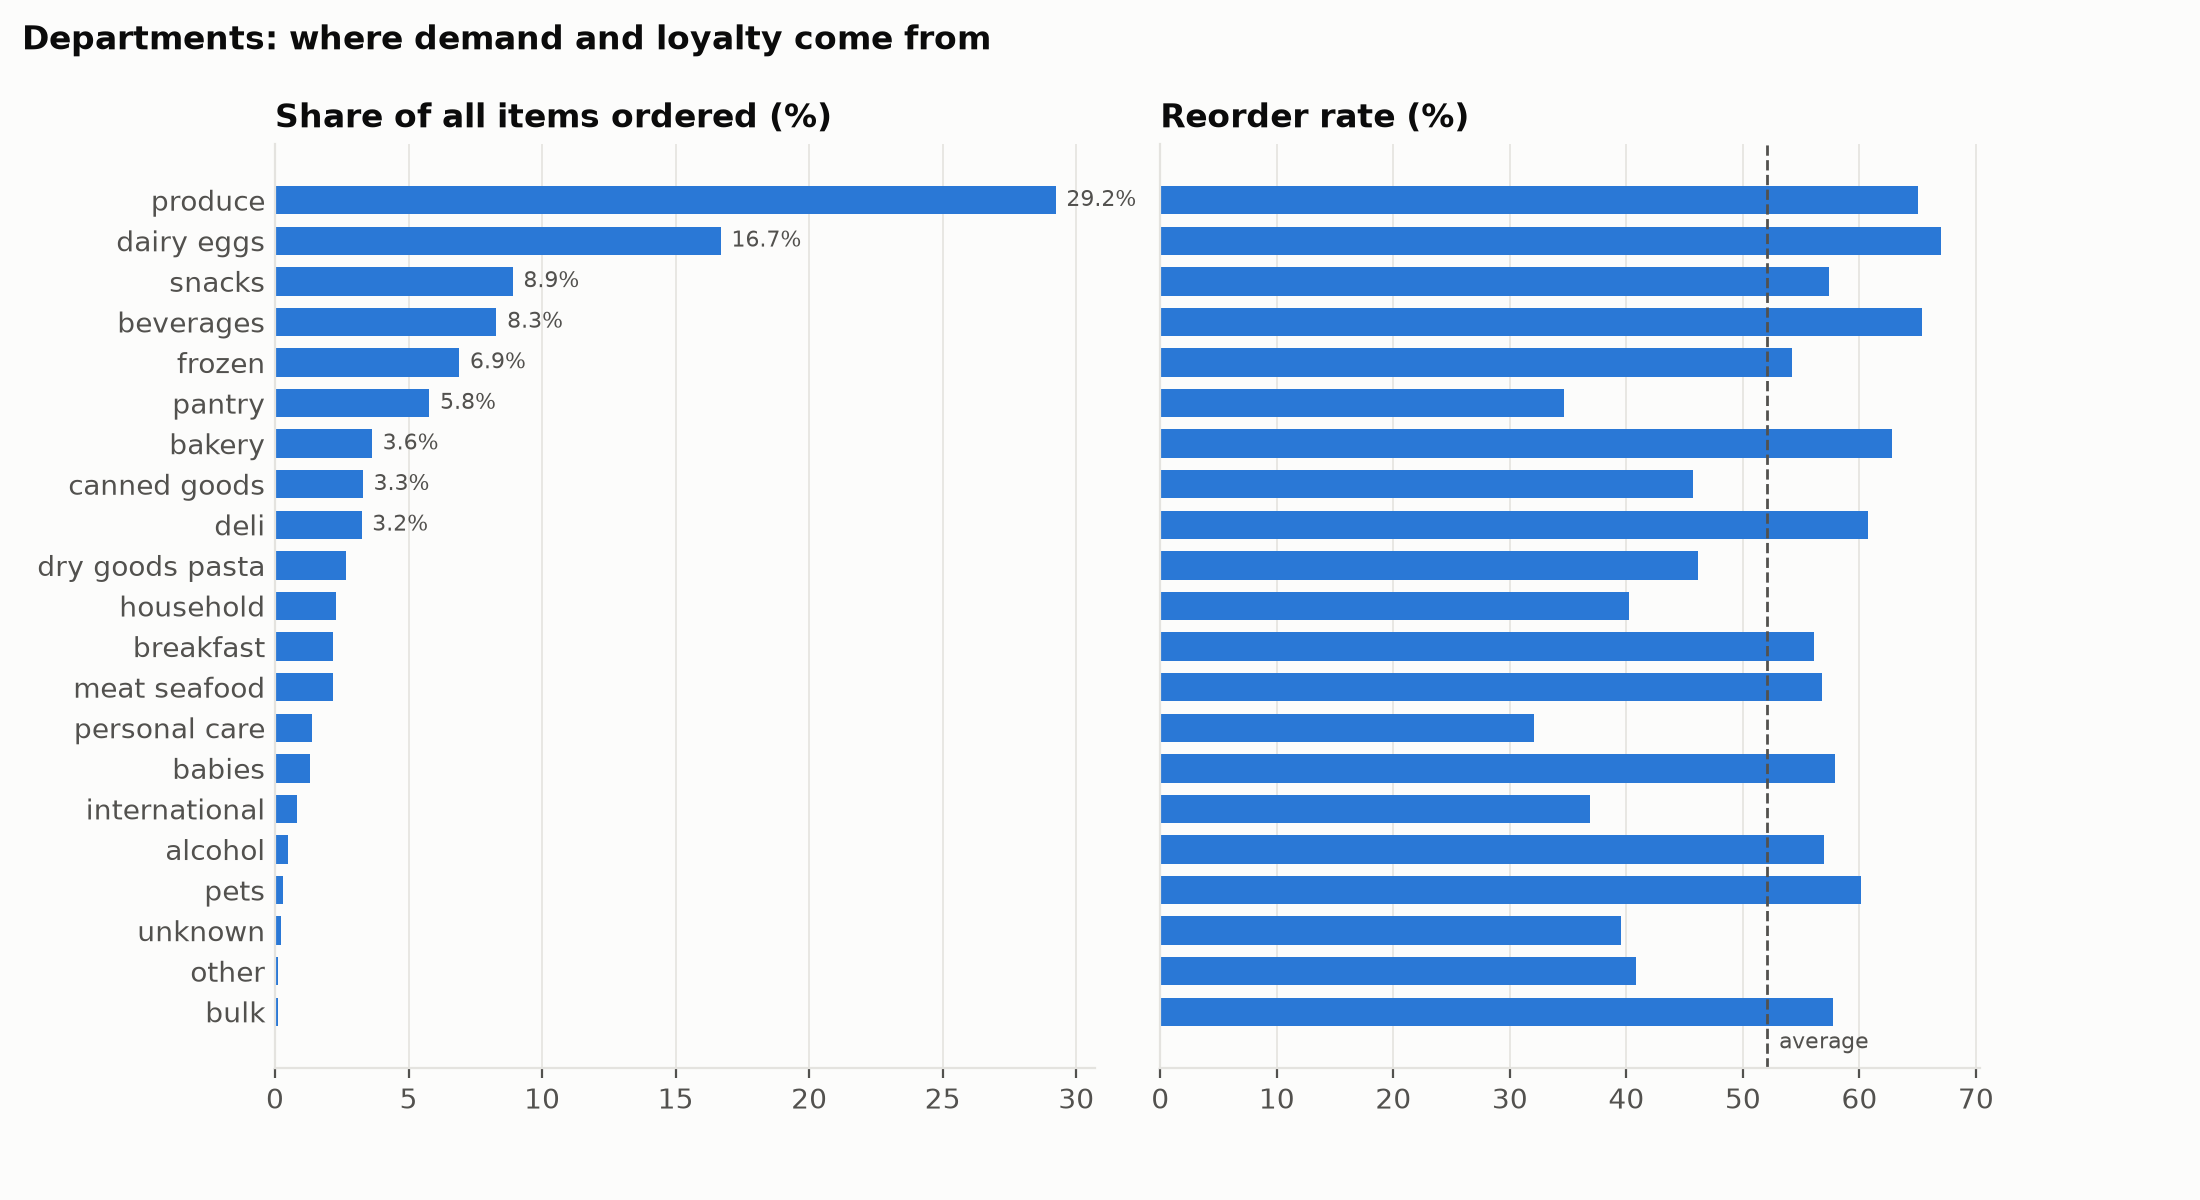

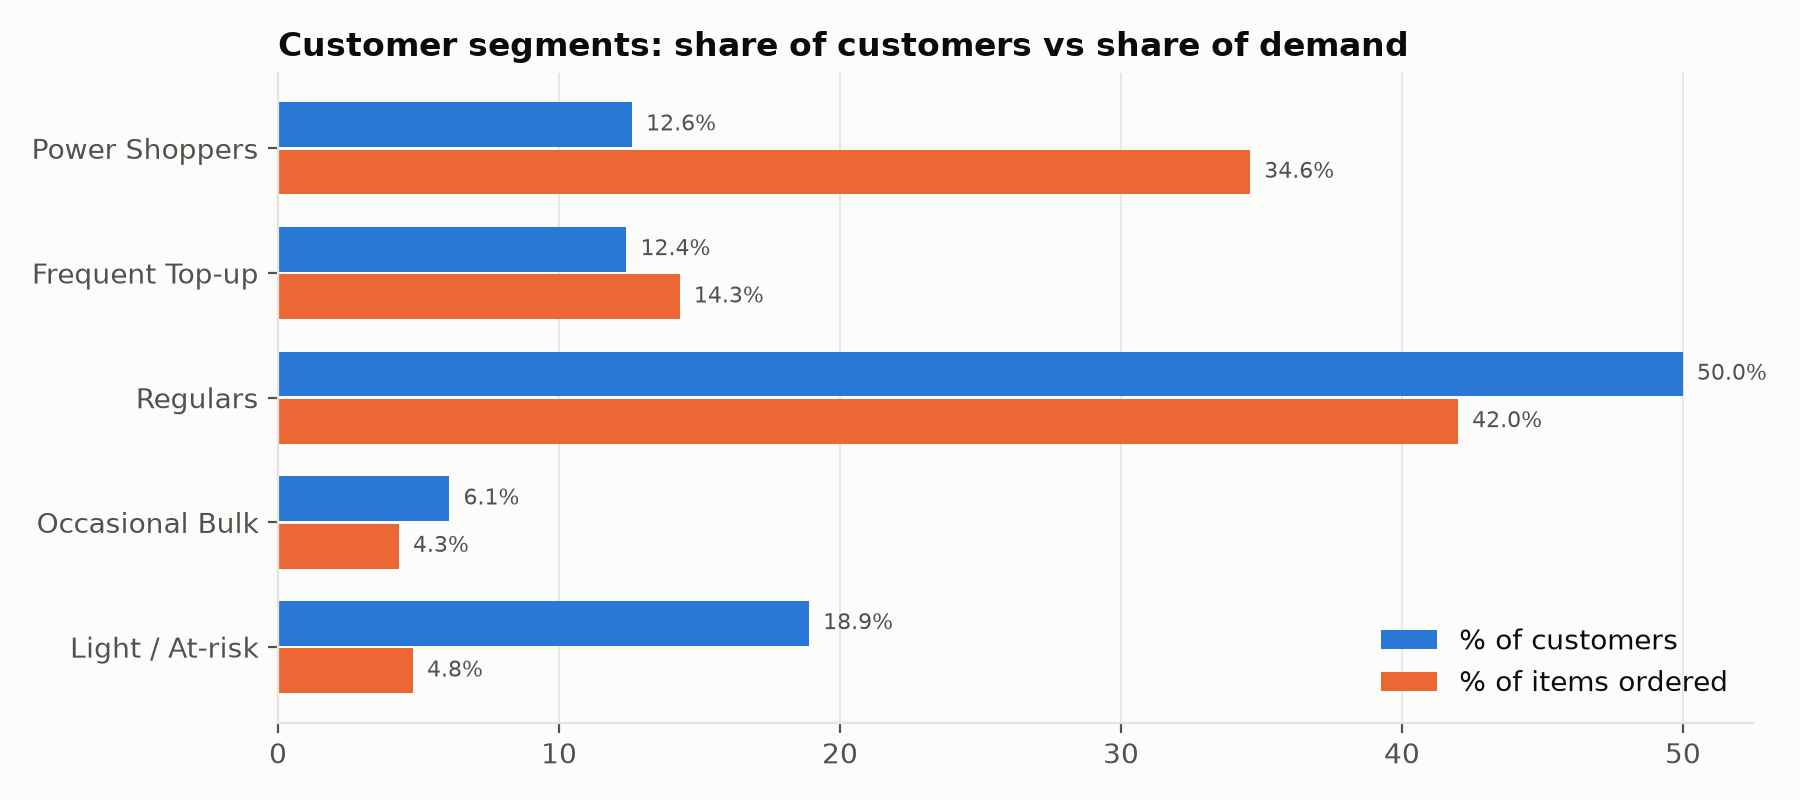

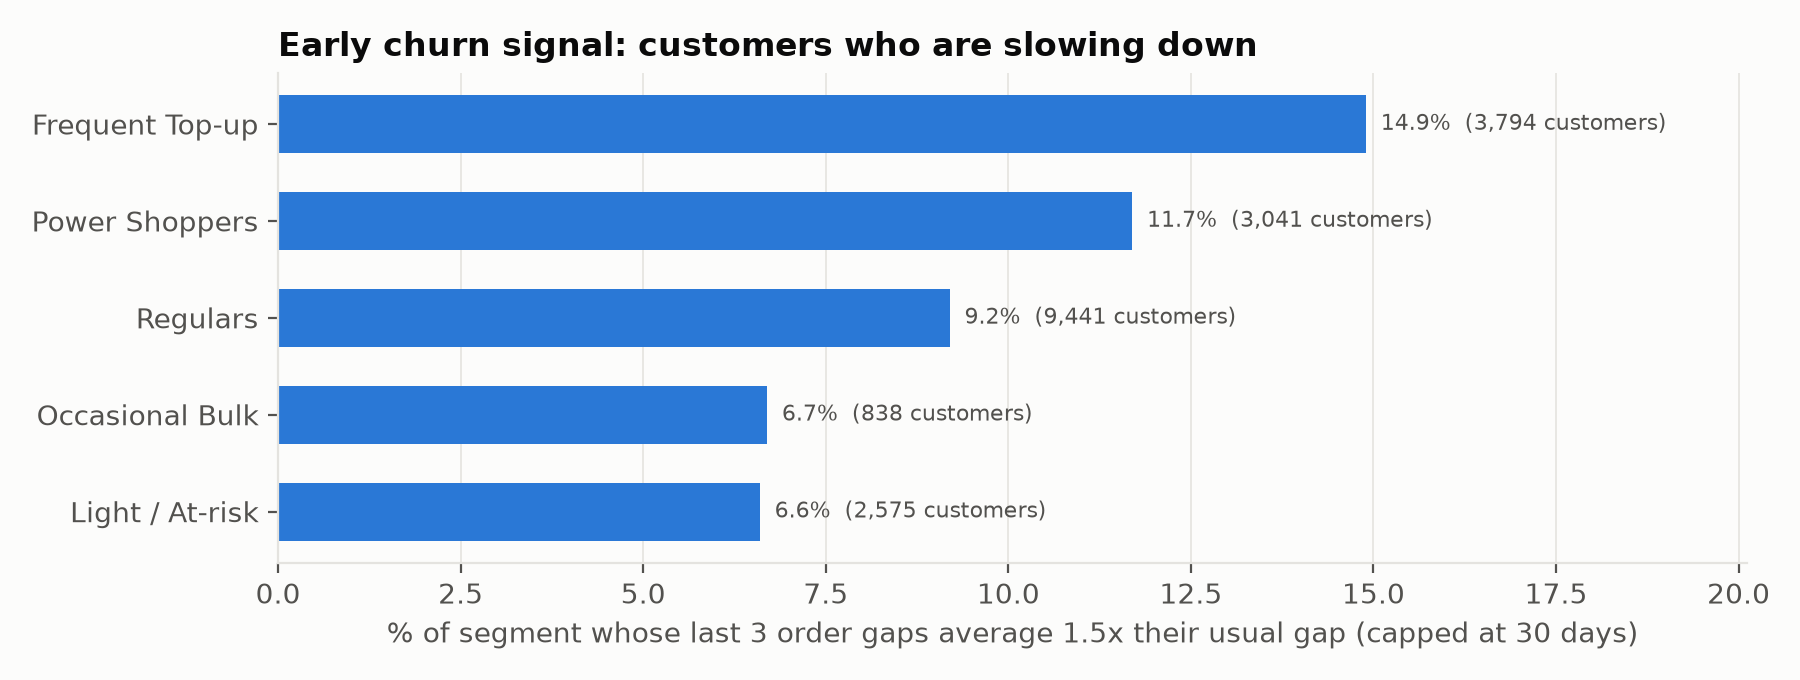

In [12]:
for f in ["01_demand_heatmap.png", "02_departments.png", "03_customer_segments.png", "04_churn_signal.png"]:
    display(Image(f"{REPORTS}/figures/{f}", width=850))

## Step 6. Live test: feed the pipeline broken data

16 records are injected into Bronze as a separate batch: a duplicate, an hour of 25, a text day of week, unknown codes, impossible combinations, orphan IDs, and 2 valid records. Silver is then re-run on all 37.3 million rows plus the bad batch.

In [13]:
PIPE = f"{PROJECT}/src/pipeline"
run = lambda *a: print(subprocess.run([sys.executable, *a], cwd=PIPE, capture_output=True, text=True).stdout)
run("demo_bad_batch.py", "inject", "--base", DATA)
run("03_silver.py", "--base", DATA, "--reports", f"{PROJECT}/outputs/demo")

orders: injected 8 records
   - exact re-send of an existing order -> duplicate removed
   - hour 25 -> hour_out_of_range
   - day 'Funday' -> bad_type
   - eval_set 'unknown' -> invalid_eval_set
   - gap on a first order -> gap_on_first_order
   - missing gap on 5th order -> missing_gap_not_first_order
   - no order_id -> missing_key
   - valid new first order -> passes to Silver
products: injected 2 records
   - department 99 does not exist -> unknown_department_id
   - blank name -> empty_name
order_products_train: injected 6 records
   - order does not exist -> orphan_order
   - product does not exist -> orphan_product
   - reordered 'yes' -> bad_type
   - cart position 0 -> invalid_cart_position
   - reorder on a first order -> reorder_on_first_order
   - valid item -> passes to Silver



  orders       bronze=  3,421,091  dupes=1  quarantined=6  silver=  3,421,084
  products     bronze=     49,690  dupes=0  quarantined=2  silver=     49,688
  order_items  bronze= 33,819,112  dupes=0  quarantined=5  silver= 33,819,107
report -> /Users/riverwolf/Documents/big data major project/outputs/demo/03_silver_dq_report.json



In [14]:
print("Quarantined rows, each with the reason it failed:")
for table in ["orders", "products", "order_items"]:
    q = spark.read.parquet(f"{DATA}/silver/_quarantine/{table}")
    cols = {"orders": ["order_id", "order_number", "order_dow", "order_hour_of_day", "eval_set", "days_since_prior_order"],
            "products": ["product_id", "product_name", "department_id"],
            "order_items": ["order_id", "product_id", "add_to_cart_order_raw", "reordered_raw"]}[table]
    print(f"\n{table}:")
    display(q.select(*cols, "_dq_reason").toPandas())

Quarantined rows, each with the reason it failed:

orders:


,order_id,order_number,order_dow,order_hour_of_day,eval_set,days_since_prior_order,_dq_reason
0,9000003,14,3,10,unknown,7.0,invalid_eval_set
1,9000001,12,3,25,prior,7.0,hour_out_of_range
2,9000004,1,3,10,prior,7.0,gap_on_first_order
3,9000005,5,3,10,prior,NaN,missing_gap_not_first_order
4,9000002,13,Funday,10,prior,7.0,bad_type
5,NaN,6,3,10,prior,7.0,missing_key



products:


,product_id,product_name,department_id,_dq_reason
0,900001,Mystery Snack,99,unknown_department_id
1,900002,,19,empty_name



order_items:


,order_id,product_id,add_to_cart_order_raw,reordered_raw,_dq_reason
0,9000006,13176,0,0,invalid_cart_position
1,99999999,24852,1,0,orphan_order
2,9000006,21137,2,1,reorder_on_first_order
3,9000006,999999,1,0,orphan_product
4,9000006,24852,1,yes,bad_type


In [15]:
demo = json.load(open(f"{PROJECT}/outputs/demo/03_silver_dq_report.json"))
pd.DataFrame({t: {k: v[k] for k in ["bronze_rows", "duplicates_removed", "quarantined", "silver_rows"]} for t, v in demo.items()}).T

,bronze_rows,duplicates_removed,quarantined,silver_rows
orders,3421091,1,6,3421084
products,49690,0,2,49688
order_items,33819112,0,5,33819107


The duplicate was removed, every broken record went to quarantine with the right reason, the 2 valid records reached Silver, and nothing was silently lost.

**Clean-up:** remove the demo batch and rebuild Silver from the real data.

In [16]:
run("demo_bad_batch.py", "remove", "--base", DATA)
run("03_silver.py", "--base", DATA, "--reports", REPORTS)

demo batch removed from Bronze; re-run 03_silver.py to rebuild Silver



  orders       bronze=  3,421,083  dupes=0  quarantined=0  silver=  3,421,083
  products     bronze=     49,688  dupes=0  quarantined=0  silver=     49,688
  order_items  bronze= 33,819,106  dupes=0  quarantined=0  silver= 33,819,106
report -> /Users/riverwolf/Documents/big data major project/outputs/pipeline/03_silver_dq_report.json



In [17]:
spark.stop()